# Chapitre 7 - Cours 1 : découper les données, par plage de clés ou par hachage

Quand le volume de données ou le débit d'écriture dépasse ce qu'une machine peut
absorber, on découpe le jeu de données en morceaux, les **shards**, et l'on place des
shards différents sur des nœuds différents. Chaque enregistrement appartient à un seul
shard ; chaque shard est en quelque sorte une petite base autonome. Ce notebook couvre
l'introduction du chapitre (avec l'encadré *Sharding and Partitioning*) et la section
*Sharding of Key-Value Data* jusqu'aux sous-sections *Sharding by Key Range* et
*Sharding by Hash of Key* (le rééquilibrage fait l'objet du cours 2).

**Plan.**

1. Sharding et réplication : deux mécanismes indépendants qui se combinent.
2. L'objectif : une répartition équitable, et ce que coûte le déséquilibre.
3. Le sharding par plage de clés : l'encyclopédie en volumes.
4. Le piège des horodatages : un point chaud qui se déplace avec le temps.
5. Le sharding par hachage : uniformité retrouvée, requêtes de plage perdues.

In [1]:
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Sharding et réplication (introduction du chapitre)

Une base distribuée répartit ses données de deux façons complémentaires :

- la **réplication** (chapitre 6) garde **une copie des mêmes données** sur
  plusieurs nœuds, pour tolérer les pannes et servir plus de lectures ;
- le **sharding** découpe les données en **morceaux disjoints**
  et place des morceaux différents sur des nœuds différents, pour stocker plus et écrire
  plus vite que ne le permettrait une seule machine.

Les deux se combinent presque toujours : chaque shard est répliqué
sur plusieurs nœuds, si bien qu'un enregistrement appartient à **un seul**
shard mais vit sur **plusieurs** machines. Avec une réplication à
leader unique, chaque shard a son propre leader, et un même nœud est
leader pour certains shards et suiveur pour d'autres. Le
choix du découpage étant largement indépendant du choix de la réplication, le reste du
chapitre ignore la réplication.

**Vocabulaire.** Le même concept porte des noms différents selon les logiciels :
*partition* (Kafka), *shard* (MongoDB, Elasticsearch, SolrCloud), *region* (HBase),
*tablet* (Bigtable), *vnode* (Cassandra, Riak), *vBucket* (Couchbase)... Le livre emploie « shard » et « sharding » ; nous dirons de même.
Rien à voir, en revanche, avec une **partition réseau** (coupure du réseau entre des nœuds,
chapitre 9).

Calculons un placement typique : 4 nœuds, 8 shards, facteur de
réplication 3. Le leader de le shard $p$ va sur le nœud $p \bmod 4$,
ses deux suiveurs sur les deux nœuds suivants.

*Encadré « Sharding and Partitioning ».* Certains systèmes distinguent les deux mots :
dans PostgreSQL, le *partitionnement* découpe une grosse table en plusieurs fichiers **sur
la même machine** (supprimer une partition entière devient instantané), tandis que le
*sharding* répartit les données **entre plusieurs machines**. Ailleurs, les deux mots sont
synonymes. Quant à l'origine du mot *shard*, l'hypothèse la plus répandue la fait remonter
au jeu en ligne *Ultima Online*, dont le monde était découpé en « éclats » parallèles.

In [2]:
N_NODES, N_SHARDS, RF = 4, 8, 3
placement = pd.DataFrame(
    [[("leader" if (p % N_NODES) == n else "suiveur" if (n - p) % N_NODES < RF else "")
      for n in range(N_NODES)] for p in range(N_SHARDS)],
    index=[f"P{p}" for p in range(N_SHARDS)], columns=[f"nœud {n}" for n in range(N_NODES)])
resume = pd.DataFrame({"leader de": (placement == "leader").sum(), "suiveur de": (placement == "suiveur").sum()})
display(placement.T)
resume.T

,P0,P1,P2,P3,P4,P5,P6,P7
nœud 0,leader,,suiveur,suiveur,leader,,suiveur,suiveur
nœud 1,suiveur,leader,,suiveur,suiveur,leader,,suiveur
nœud 2,suiveur,suiveur,leader,,suiveur,suiveur,leader,
nœud 3,,suiveur,suiveur,leader,,suiveur,suiveur,leader


,nœud 0,nœud 1,nœud 2,nœud 3
leader de,2,2,2,2
suiveur de,4,4,4,4


Chaque nœud est leader de 2 shards et suiveur de 4 autres : les
écritures (qui vont au leader) sont réparties sur les quatre machines, et la perte d'un
nœud ne fait disparaître aucune donnée. Le diagramme ci-dessous dessine
les quatre premiers shards (P0 à P3) sur les quatre nœuds.

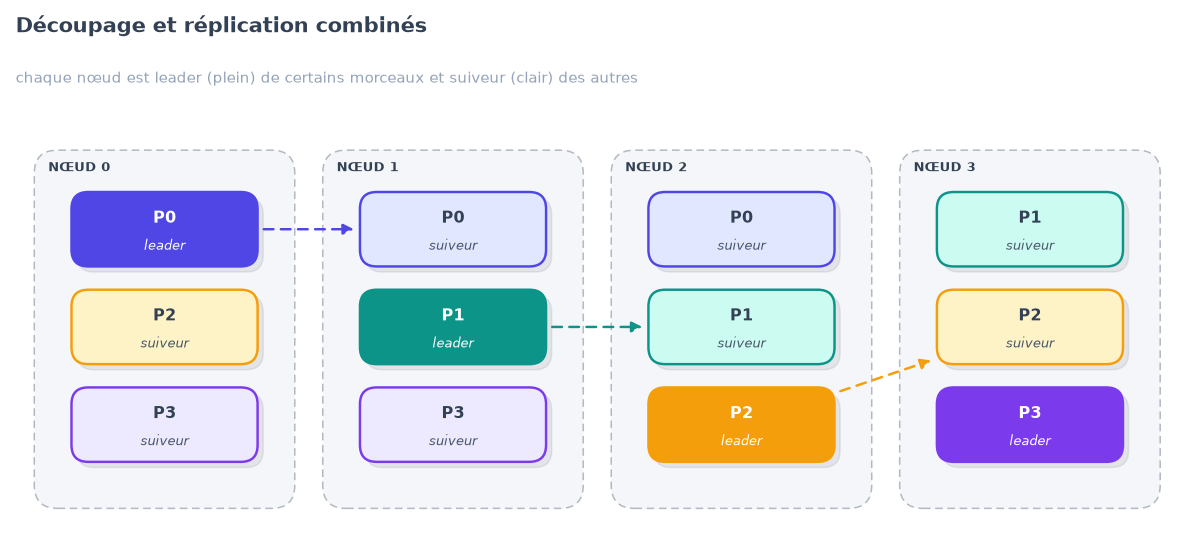

In [3]:
d = Diagram(12.6, 4.6, title="Découpage et réplication combinés",
            subtitle="chaque nœud est leader (plein) de certains morceaux et suiveur (clair) des autres")
colors = [INDIGO, TEAL, AMBER, VIOLET]
for n in range(N_NODES):
    x0 = 0.25 + n * 3.1
    d.group(x0, 0.2, x0 + 2.8, 4.05, f"nœud {n}", color=SLATE)
    row = 0
    for p in range(4):
        role = placement.iloc[p, n]
        if role:
            y = 3.2 - row * 1.05
            d.box(f"p{p}n{n}", x0 + 1.4, y, f"P{p}", sub=role, color=colors[p], w=2.0, h=0.8,
                  filled=(role == "leader"))
            row += 1
for p in range(4):
    lead = p % N_NODES
    for k in (1, 2):
        f = (lead + k) % N_NODES
        if abs(f - lead) == 1:   # flèches vers le voisin immédiat seulement, pour rester lisible
            d.arrow(f"p{p}n{lead}", f"p{p}n{f}", style="dashed", color=colors[p])
d.show()

Les flèches pointillées symbolisent le flux de réplication du leader vers un suiveur
voisin (les autres flux sont omis pour la lisibilité). Tout ce que le chapitre
6 dit de la réplication s'applique à chaque shard
séparément.

> **À retenir.** Réplication = copies identiques sur plusieurs nœuds ;
> sharding = morceaux disjoints sur des nœuds différents. On
> combine les deux : chaque enregistrement appartient à un seul
> shard, répliqué sur plusieurs nœuds.

## 2. L'objectif : une répartition équitable (section *Sharding of Key-Value Data*)

**Le but.** Si chaque nœud reçoit sa juste part, 10 nœuds stockent 10 fois plus et
servent 10 fois plus de requêtes qu'un seul. Si le découpage est **déséquilibré**
(*skewed*), le gain fond : dans le cas extrême, toute la charge tombe sur un nœud et les 9
autres attendent. On appelle **point chaud** (*hot spot*) un shard
qui reçoit une charge disproportionnée, et **clé chaude** (*hot key*) une clé
particulièrement sollicitée (le compte d'une célébrité, par exemple).

**Le formaliser.** Mesurons le déséquilibre par le rapport
$\text{déséquilibre} = \max_i L_i / \bar L$ entre la charge du nœud le plus chargé et la
charge moyenne. Le cluster sature quand son nœud le plus chargé sature : le gain réel par
rapport à une machine vaut donc $n / \text{déséquilibre}$ au lieu de $n$.

Même un découpage « aléatoire » parfait laisse un déséquilibre résiduel : c'est le
problème des **balles dans des urnes**. Répartissons au hasard $K$ clés de charge égale
dans $n = 16$ shards et mesurons le déséquilibre selon le nombre
moyen de clés par shard. Une approximation classique (loi normale
des effectifs) donne $\max/\text{moy} \approx 1 + \sqrt{2 \ln n / (K/n)}$.

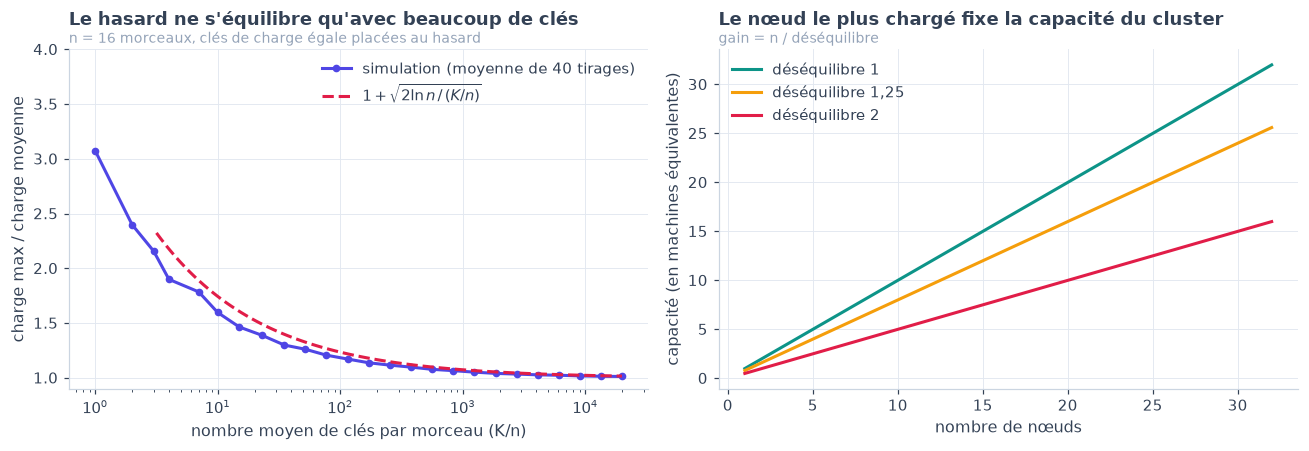

,clés par morceau,déséquilibre
0,1,3.08
5,10,1.60
10,77,1.21
15,564,1.08
20,4092,1.03


In [4]:
n = 16
per_shard = np.unique(np.logspace(0, 4.3, 26).astype(int))
rows = []
for m in per_shard:
    vals = [P.imbalance(P.shard_loads(rng.integers(0, n, m * n), n)) for _ in range(40)]
    rows.append({"clés par morceau": m, "déséquilibre": np.mean(vals)})
bib = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(bib["clés par morceau"], bib["déséquilibre"], "o-", color=INDIGO, ms=4, label="simulation (moyenne de 40 tirages)")
xs = np.logspace(0.5, 4.3, 100)
ax.plot(xs, 1 + np.sqrt(2 * np.log(n) / xs), "--", color=ROSE, label=r"$1 + \sqrt{2\ln n \,/\, (K/n)}$")
ax.set_xscale("log"); ax.set_ylim(0.9, 4)
ax.set_xlabel("nombre moyen de clés par morceau (K/n)"); ax.set_ylabel("charge max / charge moyenne")
ax.set_title("Le hasard ne s'équilibre qu'avec beaucoup de clés")
subtitle(ax, f"n = {n} morceaux, clés de charge égale placées au hasard")
ax.legend()
ax = axes[1]
for imb, c in [(1.0, TEAL), (1.25, AMBER), (2.0, ROSE)]:
    ns = np.arange(1, 33)
    ax.plot(ns, ns / imb, color=c, label=f"déséquilibre {imb:g}".replace(".", ","))
ax.set_xlabel("nombre de nœuds"); ax.set_ylabel("capacité (en machines équivalentes)")
ax.set_title("Le nœud le plus chargé fixe la capacité du cluster")
subtitle(ax, "gain = n / déséquilibre")
ax.legend()
plt.tight_layout(); plt.show()
bib.iloc[::5].round(2)

Avec quelques clés par shard, le plus chargé reçoit deux à
trois fois la moyenne ; il faut des milliers de clés par morceau pour descendre sous 5 %
d'écart. Heureusement, une base contient des millions de clés : le hasard (via une
fonction de hachage) suffit alors à équilibrer le **nombre de clés**. Ce qu'il ne règle
pas, c'est le cas où **quelques clés** concentrent la charge (cours 3), ni celui où
l'algorithme de découpage lui-même regroupe les clés actives (section 4).

> **À retenir.** Le but est de répartir données **et** requêtes uniformément ; le nœud le
> plus chargé borne la capacité du cluster (gain $n/\text{déséquilibre}$). Un placement
> aléatoire n'équilibre bien que si chaque morceau contient beaucoup de clés.

## 3. Par plage de clés (section *Sharding by Key Range*)

**L'idée.** Attribuer à chaque shard un **intervalle contigu** de
clés, comme les volumes d'une encyclopédie papier : le volume 1 va de « A » à « Bas »,
le volume 2 de « Bat » à « Cha »... Pour trouver une entrée, il suffit de connaître les
bornes : une **recherche dichotomique** dans la liste des bornes donne le volume.

**La difficulté.** Les données ne sont pas uniformes : les mots commençant par S ou C
sont bien plus nombreux que ceux commençant par X ou Q. Des volumes de largeur fixe (deux
lettres chacun) seraient très inégaux ; il faut que les **bornes s'adaptent aux
données**. Comparons sur 30 000 titres synthétiques (initiales distribuées comme dans un
dictionnaire anglais) : 13 volumes de deux lettres contre 13 volumes bornés par les
**quantiles** des titres.

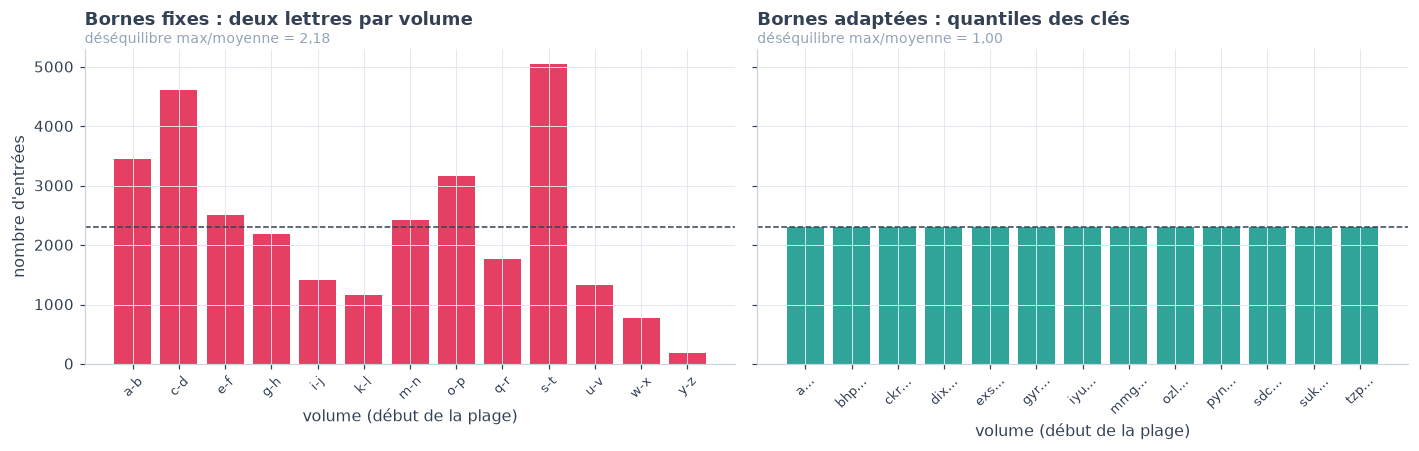

In [5]:
titles = P.synthetic_titles(30_000, seed=1)
letters = "abcdefghijklmnopqrstuvwxyz"
fixed = P.KeyRangePartitioner([letters[i] for i in range(2, 26, 2)])        # a-b, c-d, ..., y-z
adapt = P.KeyRangePartitioner.from_sample(titles, 13)
s_fixed = P.shard_loads([fixed.shard_of(t) for t in titles], 13)
s_adapt = P.shard_loads([adapt.shard_of(t) for t in titles], 13)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
lab_fixed = [f"{letters[2 * i]}-{letters[2 * i + 1]}" for i in range(13)]
b = [""] + adapt.boundaries
lab_adapt = [f"{(b[i] or 'a')[:3]}…" for i in range(13)]
for ax, s, lab, c, t in [(axes[0], s_fixed, lab_fixed, ROSE, "Bornes fixes : deux lettres par volume"),
                         (axes[1], s_adapt, lab_adapt, TEAL, "Bornes adaptées : quantiles des clés")]:
    ax.bar(range(13), s, color=c, alpha=0.85)
    ax.axhline(len(titles) / 13, color=SLATE, ls="--", lw=1)
    ax.set_xticks(range(13)); ax.set_xticklabels(lab, rotation=45, fontsize=8.5)
    ax.set_title(t)
    subtitle(ax, f"déséquilibre max/moyenne = {P.imbalance(s):.2f}".replace(".", ","))
    ax.set_xlabel("volume (début de la plage)")
axes[0].set_ylabel("nombre d'entrées")
plt.tight_layout(); plt.show()

Avec des bornes fixes, le volume « s-t » contient plus de deux fois la moyenne et le
volume « y-z » presque rien ; avec les quantiles, les 13 volumes sont égaux à une entrée
près. Les bornes peuvent être choisies **à la main** par un administrateur (Vitess,
couche de sharding pour MySQL) ou **automatiquement** par la
base (Bigtable, HBase, le mode par plage de MongoDB, RethinkDB, FoundationDB, CockroachDB) :
le cours 2 montre comment elles évoluent quand les données grossissent.

**Le grand avantage : les requêtes de plage.** Dans chaque shard,
les clés sont rangées dans l'ordre (B-tree ou SSTables, chapitre 4). Toutes les
entrées qui commencent par « cha » sont donc **contiguës**, dans un seul
shard ou deux voisins : la recherche par préfixe ne touche
qu'une petite fraction du cluster.

In [6]:
def prefix_query(part, prefix):
    lo, hi = prefix, prefix + "~"          # « ~ » est après toutes les lettres en ASCII
    return part.shards_for_range(lo, hi)

for prefix in ["c", "ca", "s", "x"]:
    shards = prefix_query(adapt, prefix)
    n_hits = sum(t.startswith(prefix) for t in titles)
    print(f"préfixe {prefix!r:6} : {n_hits:5d} entrées, {len(shards)} volume(s) interrogé(s) sur 13 : {shards}")

préfixe 'c'    :  2886 entrées, 2 volume(s) interrogé(s) sur 13 : [1, 2]
préfixe 'ca'   :   101 entrées, 1 volume(s) interrogé(s) sur 13 : [1]
préfixe 's'    :  3481 entrées, 3 volume(s) interrogé(s) sur 13 : [9, 10, 11]
préfixe 'x'    :    37 entrées, 1 volume(s) interrogé(s) sur 13 : [12]


Même le préfixe « s », qui couvre près de 3 500 entrées (12 % du total), ne touche que 3
volumes sur 13 ; les préfixes plus longs n'en touchent qu'un.
On peut aussi utiliser la clé comme un **index concaténé** (chapitre 4) :
avec une clé `capteur/année-mois-jour-heure`, une seule requête de plage récupère toutes
les mesures d'un capteur sur un mois.

> **À retenir.** Par plage de clés : chaque morceau possède un intervalle contigu, les
> bornes doivent suivre la distribution des données (quantiles), et les requêtes de
> plage restent efficaces car les clés voisines sont rangées ensemble.

## 4. Le piège des horodatages (section *Sharding by Key Range*, suite)

**Le scénario.** Un réseau de 200 capteurs envoie une mesure toutes les dix minutes ; la
clé est l'**horodatage**. Les shards correspondent alors à des
**intervalles de temps** (ici une journée chacun). Les requêtes « toutes les mesures
de mardi » sont idéales... mais **toutes les écritures** tombent sur le morceau du jour
courant : un point chaud qui se déplace avec le temps, pendant que les autres morceaux
dorment.

**Le remède du livre.** Préfixer la clé par l'identifiant du capteur :
`(capteur, horodatage)`. Le découpage par plage porte alors d'abord sur le capteur (ici
10 morceaux de 20 capteurs), et comme les 200 capteurs écrivent en même temps, les
écritures se répartissent. Simulons 30 jours et comptons les écritures par morceau et par
heure.

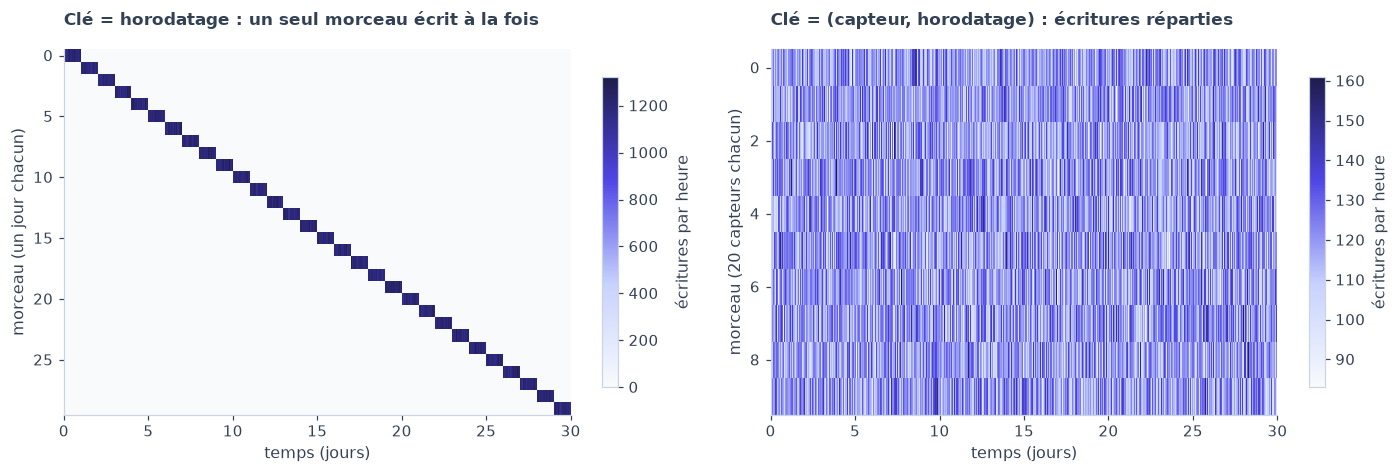

écritures/heure reçues par le morceau le plus chargé : 1199 (horodatage) contre 137 (capteur d'abord) ; total 1199/h


In [7]:
DAYS = 30
sid, t = P.sensor_readings(n_sensors=200, duration=DAYS * 86400, rate=1 / 600, seed=2)
hour = (t // 3600).astype(int)
shard_time = (t // 86400).astype(int)                      # clé = horodatage : un morceau par jour
shard_sensor = sid // 20                                   # clé = (capteur, horodatage) : 10 morceaux
H = DAYS * 24
heat_time = np.zeros((DAYS, H)); np.add.at(heat_time, (shard_time, hour), 1)
heat_sensor = np.zeros((10, H)); np.add.at(heat_sensor, (shard_sensor, hour), 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, heat, ttl, ylab in [(axes[0], heat_time, "Clé = horodatage : un seul morceau écrit à la fois", "morceau (un jour chacun)"),
                            (axes[1], heat_sensor, "Clé = (capteur, horodatage) : écritures réparties", "morceau (20 capteurs chacun)")]:
    im = ax.imshow(heat, aspect="auto", cmap="ddia_seq", interpolation="nearest",
                   extent=(0, DAYS, heat.shape[0] - 0.5, -0.5))
    ax.set_xlabel("temps (jours)"); ax.set_ylabel(ylab); ax.set_title(ttl, fontsize=11)
    ax.grid(False)
    plt.colorbar(im, ax=ax, label="écritures par heure", shrink=0.85)
plt.tight_layout(); plt.show()

per_hour_max_time = heat_time.max(axis=0).mean()
per_hour_max_sensor = heat_sensor.max(axis=0).mean()
print(f"écritures/heure reçues par le morceau le plus chargé : {per_hour_max_time:.0f} (horodatage) "
      f"contre {per_hour_max_sensor:.0f} (capteur d'abord) ; total {heat_time.sum(axis=0).mean():.0f}/h")

À gauche, la diagonale : à chaque heure, 100 % des écritures (environ 1 200 par heure)
visent un seul morceau sur 30. À droite, les 10 morceaux reçoivent chacun environ un
dixième du flux (le plus chargé, environ 137 par heure en moyenne, dépasse un peu la part
équitable de 120 à cause du hasard des arrivées). Le prix à payer apparaît **à la
lecture** : pour récupérer les mesures de tous les capteurs sur une période, il faut
désormais une requête de plage **par capteur** (dans le pire cas sur tous les morceaux).

In [8]:
pd.DataFrame({
    "clé": ["horodatage", "(capteur, horodatage)"],
    "morceaux écrits à un instant donné": [1, 10],
    "« tous les capteurs, mardi » : requêtes de plage": [1, 200],
    "« tous les capteurs, mardi » : morceaux touchés": [1, 10],
    "« capteur 42, tout le mois » : morceaux touchés": [DAYS, 1],
})

,clé,morceaux écrits à un instant donné,"« tous les capteurs, mardi » : requêtes de plage","« tous les capteurs, mardi » : morceaux touchés","« capteur 42, tout le mois » : morceaux touchés"
0,horodatage,1,1,1,30
1,"(capteur, horodatage)",10,200,10,1


> **À retenir.** Une clé monotone (horodatage, compteur auto-incrémenté) placée en tête
> d'une clé partitionnée par plage concentre **toutes** les écritures sur le dernier
> morceau. Mettre une dimension « large » en tête (capteur, utilisateur) répartit les
> écritures, au prix de requêtes de plage multiples quand on veut toutes les entités.

## 5. Par hachage de la clé (section *Sharding by Hash of Key*)

**L'idée.** Si l'on ne tient pas à garder ensemble les clés voisines (identifiants
d'utilisateurs, de commandes...), on applique d'abord une **fonction de hachage** à la
clé : une bonne fonction transforme des entrées très semblables en valeurs d'apparence
aléatoire, uniformément réparties sur $[0, 2^{32})$ (ou $[0, 2^{64})$). On découpe
ensuite l'**espace des hachés** en plages, une par shard.

**Une exigence : la stabilité.** La fonction n'a pas besoin d'être cryptographique
(MongoDB utilise MD5, Cassandra Murmur3), mais elle doit donner **le même résultat dans
tous les processus**. Ce n'est pas le cas de toutes les fonctions intégrées aux langages,
conçues pour des tables de hachage en mémoire : `hash()` de Python, par exemple, est
**randomisé** pour les chaînes à chaque lancement de l'interpréteur (une protection contre
les attaques par collisions). Vérifions-le en lançant trois interpréteurs.

In [9]:
code = "from ddia.partitioning import stable_hash; print(hash('utilisateur:42'), stable_hash('utilisateur:42'))"
rows = []
for seed in ["1", "2", "3"]:
    out = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True,
                         env={"PYTHONHASHSEED": seed, "PATH": ""}).stdout.split()
    rows.append({"processus": f"interpréteur {seed}", "hash() de Python": int(out[0]),
                 "stable_hash (MD5, 32 bits)": int(out[1]),
                 "morceau = hash() mod 8": int(out[0]) % 8, "morceau = stable_hash mod 8": int(out[1]) % 8})
pd.DataFrame(rows).set_index("processus")

,hash() de Python,"stable_hash (MD5, 32 bits)",morceau = hash() mod 8,morceau = stable_hash mod 8
processus,,,,
interpréteur 1,1804101317397486892,1430235784,4,0
interpréteur 2,-7004959544995988068,1430235784,4,0
interpréteur 3,-5673900409398286014,1430235784,2,0


Avec `hash()`, la même clé irait dans un morceau différent selon le processus qui la
traite : une écriture faite par un serveur serait introuvable par un autre. Avec MD5, le
résultat est identique partout.

Regardons maintenant ce que fait le hachage à des clés **très semblables** : des
horodatages consécutifs, en secondes. Leur haché est uniforme, et le flux d'écritures de
la section 4 se répartit sur tous les morceaux.

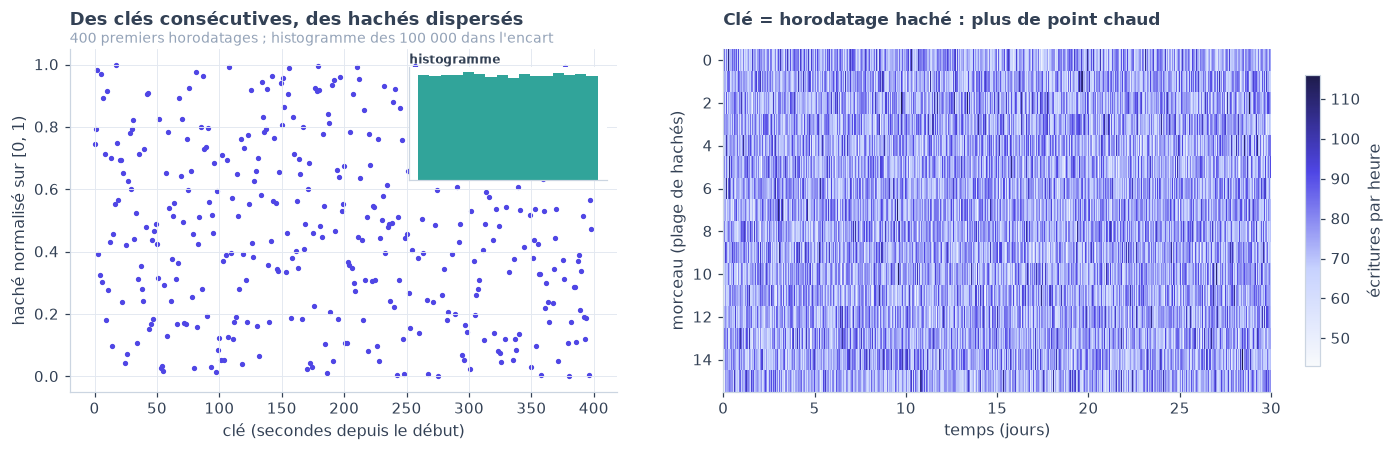

déséquilibre des écritures par heure : 1.25 (16 morceaux, ~75 écritures par morceau et par heure)


In [10]:
ts_keys = np.arange(1_600_000_000, 1_600_000_000 + 100_000)          # 100 000 secondes consécutives
u = P.hash_unit(ts_keys)
N_H = 16
shard_hash = (P.hash_unit(t.astype(np.int64)) * N_H).astype(int)       # mesures de la section 4
heat_hash = np.zeros((N_H, H)); np.add.at(heat_hash, (shard_hash, hour), 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.scatter(ts_keys[:400] - ts_keys[0], u[:400], s=6, color=INDIGO)
ax.set_xlabel("clé (secondes depuis le début)"); ax.set_ylabel("haché normalisé sur [0, 1)")
ax.set_title("Des clés consécutives, des hachés dispersés")
subtitle(ax, "400 premiers horodatages ; histogramme des 100 000 dans l'encart")
ins = ax.inset_axes([0.62, 0.62, 0.36, 0.33])
ins.set_facecolor("white"); ins.set_zorder(5)
ins.hist(u, bins=16, color=TEAL, alpha=0.85); ins.set_xticks([]); ins.set_yticks([]); ins.grid(False)
ins.set_title("histogramme", fontsize=8, pad=2)
ax = axes[1]
im = ax.imshow(heat_hash, aspect="auto", cmap="ddia_seq", interpolation="nearest",
               extent=(0, DAYS, N_H - 0.5, -0.5))
ax.set_xlabel("temps (jours)"); ax.set_ylabel("morceau (plage de hachés)"); ax.grid(False)
ax.set_title("Clé = horodatage haché : plus de point chaud", fontsize=11)
plt.colorbar(im, ax=ax, label="écritures par heure", shrink=0.85)
plt.tight_layout(); plt.show()
print(f"déséquilibre des écritures par heure : {np.mean(heat_hash.max(axis=0) / heat_hash.mean(axis=0)):.2f} "
      f"(16 morceaux, ~{heat_hash.mean():.0f} écritures par morceau et par heure)")

Le point chaud a disparu (le léger déséquilibre résiduel, d'environ 1,25, est celui des
balles dans des urnes de la section 2 avec seulement 75 écritures par morceau et par
heure). Mais l'ordre des clés est **détruit** : une requête de plage sur la clé, qui
touchait un ou deux morceaux, doit maintenant interroger presque tout le cluster.
Mesurons le nombre de morceaux à interroger pour une plage de $w$ clés consécutives, avec
16 morceaux, en plage de clés et en plage de hachés. Pour le hachage, la probabilité qu'un
morceau ne contienne aucune des $w$ clés vaut $(1 - 1/n)^w$, d'où une espérance de
$n\,(1 - (1-1/n)^w)$ morceaux touchés.

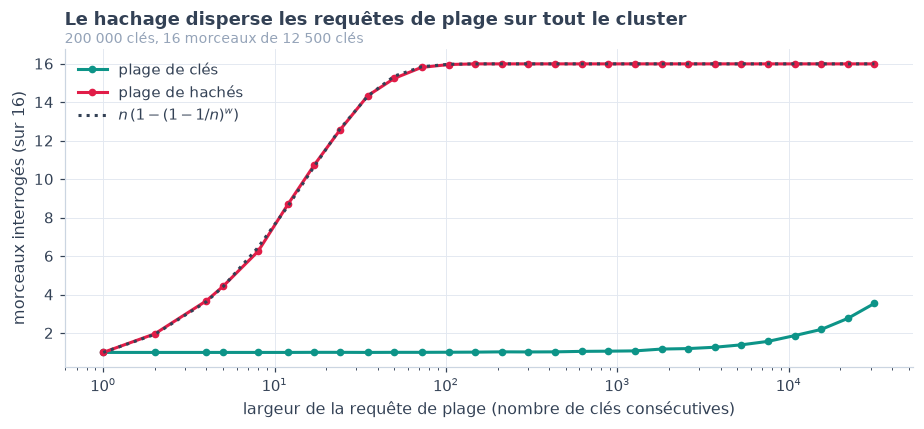

In [11]:
keys_sorted = np.arange(200_000)
kr16 = P.KeyRangePartitioner(list(np.quantile(keys_sorted, np.arange(1, 16) / 16)))
widths = np.unique(np.logspace(0, 4.5, 30).astype(int))
range_touched, hash_touched = [], []
for w in widths:
    starts = rng.integers(0, keys_sorted.size - w, 200)
    range_touched.append(np.mean([len(kr16.shards_for_range(s, s + w - 1)) for s in starts]))
    hash_touched.append(np.mean([np.unique((P.hash_unit(np.arange(s, s + w)) * 16).astype(int)).size
                                 for s in starts[:60]]))
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(widths, range_touched, "o-", ms=4, color=TEAL, label="plage de clés")
ax.plot(widths, hash_touched, "o-", ms=4, color=ROSE, label="plage de hachés")
ax.plot(widths, 16 * (1 - (1 - 1 / 16) ** widths), ":", color=SLATE, label=r"$n\,(1-(1-1/n)^w)$")
ax.set_xscale("log"); ax.set_xlabel("largeur de la requête de plage (nombre de clés consécutives)")
ax.set_ylabel("morceaux interrogés (sur 16)")
ax.set_title("Le hachage disperse les requêtes de plage sur tout le cluster")
subtitle(ax, "200 000 clés, 16 morceaux de 12 500 clés")
ax.legend()
plt.tight_layout(); plt.show()

Une plage de 50 clés touche en moyenne un seul morceau en partitionnement par plage, et
déjà 15 sur 16 avec le hachage. C'est le compromis fondamental du chapitre.

**Le meilleur des deux : la clé composée.** On peut ne hacher que la **première partie**
de la clé (la clé de partitionnement) et trier les enregistrements de chaque morceau par
le reste de la clé. C'est le modèle de Cassandra : avec une clé primaire
`(id_utilisateur, horodatage)`, le haché de l'utilisateur choisit le morceau, et toutes
ses mises à jour y sont rangées par date. La requête « messages de l'utilisateur 42 entre
lundi et mercredi » ne touche alors qu'un seul morceau, tandis que des utilisateurs
différents se répartissent uniformément. Implémentons cette idée en quelques lignes.

In [12]:
import bisect


class CompositeKeyStore:
    """Clé (clé_de_partitionnement, clé_de_tri) : haché de la première partie, tri par la seconde."""

    def __init__(self, n_shards):
        self.n = n_shards
        self.shards = [dict() for _ in range(n_shards)]       # morceau -> {clé de part. : liste triée}

    def shard(self, pk):
        return P.stable_hash(pk) % self.n

    def put(self, pk, sk, value):
        bisect.insort(self.shards[self.shard(pk)].setdefault(pk, []), (sk, value))

    def range(self, pk, lo, hi):
        rows = self.shards[self.shard(pk)].get(pk, [])
        i, j = bisect.bisect_left(rows, (lo,)), bisect.bisect_right(rows, (hi, chr(0x10FFFF)))
        return rows[i:j], 1                                    # un seul morceau interrogé


store = CompositeKeyStore(16)
users = rng.integers(0, 2_000, 60_000)
dates = rng.uniform(0, 30, 60_000)
for u_, d_ in zip(users, dates):
    store.put(f"user:{u_}", round(float(d_), 4), "message")
rows42, touched = store.range("user:42", 7.0, 9.0)
sizes = [sum(len(v) for v in s.values()) for s in store.shards]
print(f"utilisateur 42, jours 7 à 9 : {len(rows42)} messages, {touched} morceau interrogé sur 16")
print(f"messages par morceau : min {min(sizes)}, max {max(sizes)} (déséquilibre {P.imbalance(sizes):.2f})")

utilisateur 42, jours 7 à 9 : 4 messages, 1 morceau interrogé sur 16
messages par morceau : min 3205, max 4516 (déséquilibre 1.20)


Les morceaux restent raisonnablement équilibrés (déséquilibre de 1,2 : avec 2 000
utilisateurs, chaque morceau n'en reçoit que 125 en moyenne, c'est l'effet « balles dans
des urnes » de la section 2), et une requête de plage **à utilisateur fixé** ne touche qu'un morceau.
Seules les requêtes de plage qui traversent plusieurs valeurs de la clé de
partitionnement (« tous les messages de mardi ») redeviennent coûteuses.

*Encadré « Partitioning and Range Queries in Data Warehouses ».* Les entrepôts de données
reprennent la même idée sous d'autres noms : dans BigQuery, la clé de partitionnement
choisit la partition et les *cluster columns* fixent l'ordre des lignes à l'intérieur ;
Snowflake découpe automatiquement en micro-partitions et laisse définir des *cluster
keys* ; Delta Lake offre les deux. Ranger les données par une colonne améliore non
seulement les parcours de plage, mais aussi la compression et le filtrage (chapitre
4, stockage en colonnes).

> **À retenir.** Le hachage rend la répartition uniforme même pour des clés très
> semblables, à condition d'utiliser une fonction **stable** entre processus. Il détruit
> l'ordre des clés : les requêtes de plage touchent tout le cluster, sauf si l'on ne hache
> que la première partie d'une clé composée.

## Synthèse

- Le **sharding** découpe les données en morceaux disjoints
  placés sur des nœuds différents ; il se combine avec la **réplication**
  (chapitre 6), qui copie chaque morceau sur plusieurs nœuds.
- Le but est l'**équité** : le nœud le plus chargé borne la capacité du cluster. Le
  déséquilibre naît des données (distribution des clés), de l'algorithme (clés voisines
  regroupées) et des requêtes (clés chaudes, cours 3).
- **Par plage de clés** : bornes adaptées aux données, requêtes de plage efficaces, mais
  point chaud dès que les écritures visent des clés voisines (horodatages).
- **Par hachage** : répartition uniforme, mais plus de requêtes de plage sur la clé ; la
  **clé composée** (haché de la première partie, tri par le reste) récupère les requêtes
  de plage à clé de partitionnement fixée.
- Une même base doit aussi pouvoir **changer** son découpage quand on ajoute des nœuds :
  c'est le rééquilibrage (cours 2). Le routage des requêtes et les clés chaudes sont au
  cours 3, les index secondaires au cours 4.
- Liens : structures triées dans chaque morceau (chapitre 4), latence de queue
  des requêtes réparties (chapitre 2), transactions qui traversent
  plusieurs morceaux (chapitre 8).